# Toward DEMO Power Plant Concept Selection Under Epistemic Uncertainty: the Major Radius of an EU DEMO-like Tokamak in a Related PROCESS Model

__Enrique Miralles-Dolz__, Institute for Risk and Uncertainty, University of Liverpool, Liverpool L69 3BX, U.K.

__Alexander Pearce__ and __James Morris__, U.K. Atomic Energy Authority, Culham Science Center, Abingdon OX14 3DB, U.K.

__Edoardo Patelli__, Center for Intelligent Infrastructure, University of Strathclyde, Glasgow G1 1XQ, U.K.

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

The fusion systems code PROCESS sizes a tokamak power plant by solving one constrained optimisation: here, the smallest plasma major radius $R_0$ that still delivers 400 MW of net electric power with a 2-hour burn, the problem of [[1]](https://doi.org/10.1109/TPS.2022.3180233). The paper's input deck and PROCESS version are not published, so we ran 64 optimisations of a related model, not the paper's: PROCESS v3.4.2 on its public example large-tokamak deck edited to the paper's six uncertain inputs (H-factor, divertor limit, core radius, tungsten fraction, elongation and helium fraction), and estimated the active subspace of the optimal $R_0$ from the 62 converged runs with a global quadratic fit (no gradients). $R_0$ has a one-dimensional active subspace: the first eigenvalue holds 96.5 % of the trace, the rest lie at the quadratic fit's noise floor, and the direction, dominated by the H-factor and the elongation, is stable under leave-one-out and other estimators. The size of $\lambda_1/\lambda_2$ is not determined by these runs (its denominator is fit noise, and the stored optima depend on the optimiser's starting point at least at one of two rows checked). A quadratic in the one active variable predicts $R_0$ with leave-one-out $R^2 = 0.973$.

## Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs $\mathbf x \in [-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x) \approx g(\mathbf W_1^T \mathbf x)$, which a sufficient summary plot of $f$ against $\mathbf W_1^T\mathbf x$ shows. When gradients are not available, $\mathbf C$ can be estimated from a least-squares quadratic fit of $f$ (the QPHD estimator used below). See [[2]](https://doi.org/10.1137/1.9781611973860).

## The model

**PROCESS** [[3]](https://doi.org/10.1016/j.fusengdes.2014.09.018), [[4]](https://doi.org/10.1016/j.fusengdes.2016.01.007) is UKAEA's systems code for fusion power plants: 0-D and 1-D models of the plasma (profiles with a pedestal, the IPB98(y,2) confinement scaling, impurity radiation, bootstrap current, fusion power), the coils, the radial build, the power conversion and the costs. Given the six inputs $\mathbf x$ below, PROCESS solves

$$
R_0(\mathbf x) = \min_{\mathbf u}\ R_0 \quad\text{subject to}\quad \mathbf c_{eq}(\mathbf u;\mathbf x) = 0,\quad \mathbf c_{in}(\mathbf u;\mathbf x) \ge 0,\quad \mathbf u_l \le \mathbf u \le \mathbf u_u,
$$

over 17 iteration variables $\mathbf u$ (among them $R_0$, the toroidal field $B_T$, the electron temperature and density, $\beta$, $q_{95}$, the central-solenoid and TF-coil dimensions, the TF current per turn and the xenon seeding fraction), with 3 equality constraints (beta consistency, plasma power balance, radial build) and 23 inequality constraints, among them net electric power $P_{net} \ge 400$ MW, burn time $t_{burn} \ge 7200$ s, the divertor limit $P_{sep}B_T/(q_{95} A R_0) \le$ the input limit, the density and beta limits, a 14 T peak TF field, coil stress and quench limits, a 2 MW/m² neutron wall load, and $\tau_\alpha/\tau_E \ge 5$. The solver is VMCON, a sequential quadratic programming method; a run is *converged* (PROCESS's "feasible solution", `ifail = 1`) when it meets all constraints at a local optimum. Our **quantity of interest** is the optimal major radius $R_0(\mathbf x)$ in metres, the output of the paper ("one of the main drivers of the power plant size, an indicator of cost, and overall feasibility", p. 4442). At every converged run $P_{net}$ and $t_{burn}$ sit on their limits (printed below), so $R_0$ is the size of the smallest machine that meets the targets.

**Input deck.** The paper's "European H-mode DEMO baseline" deck is not published. We used the closest deck in the PROCESS repository, `examples/data/large_tokamak_IN.DAT` (v3.4.2; "Generic large tokamak", J. Morris, UKAEA, 2023, an EU-DEMO-like design with the same objective, 400 MW net electric, 2 h burn, elongation 1.85, H = 1.1 and core radius 0.75), with these changes (`make_template.py`): the H-factor and the He-4 fraction are inputs, not iteration variables; the divertor limit is the paper's 9.2 MW T/m at baseline instead of 10; the W fraction baseline is $5\times10^{-5}$ instead of $5\times10^{-6}$; the bounds on $R_0$ are widened from [8, 9] m to [6, 13] m (the stock bounds would cut off the paper's range); and VMCON is capped at 50 iterations per attempt. Each run starts from the optimum at the paper's baseline point (shipped as `baseline_warmstart.json`). The PROCESS version of the paper (2022, then partly Fortran) is not stated, and the code has changed much since, so these runs are new runs of a related model, not a reproduction of the paper's numbers.

**Inputs.** The paper's Table I (p. 4441): six intervals, sampled uniformly (the W fraction too, uniform and not log-uniform: "a uniform distribution was chosen for the uncertain input parameters", p. 4442). The paper stresses that the intervals carry no probability; the uniform density is only for sampling, and it is the density $\rho$ of the active subspace here. Input 3 follows Table I, which names it "Core Radius" with baseline 0.75, the deck's normalised core radius `radius_plasma_core_norm`; the paper's prose for item 3 ("the parameter representing the fraction of radiation that is released from the core") describes instead PROCESS's core-radiation fraction (`f_p_plasma_core_rad_reduction`, 0.6 in the deck), which is held fixed here. The table is printed from the names and bounds in the code cell.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
import active_subspaces as ac

SEED = 675                        # the only seed in this notebook (bootstrap, Sobol' points)
t_start = time.perf_counter()
warnings.filterwarnings('ignore', category=ac.ValidityWarning)   # QPHD on a uniform space; see below
warnings.formatwarning = lambda msg, cat, *args, **kw: f'{cat.__name__}: {msg}\n'

NAMES = ['hfact', 'psepbqar_max', 'core_radius', 'f_w', 'kappa', 'f_he']
LABELS = ['$H$', r'$(P_{sep}B_T/qAR_0)_{max}$', r'$\rho_{core}$', '$f_W$', r'$\kappa_{sep}$', '$f_{He}$']
PAPER = ['H-factor', 'Divertor limit', 'Core radius', 'W impurity fraction', 'Plasma elongation',
         'Thermal He-4 fraction']
UNITS = ['-', 'MW T/m', '-', '-', '-', '-']
PROCESS_VAR = ['hfact', 'p_div_bt_q_aspect_rmajor_max_mw', 'radius_plasma_core_norm',
               'f_nd_impurity_electrons(14)', 'kappa', 'f_nd_alpha_thermal_electron']
# Table I of the paper (p. 4441): lower bound, upper bound, baseline (W baseline printed "50^-5")
LOWER = np.array([1.0, 8.7, 0.6, 1e-5, 1.75, 0.06])
UPPER = np.array([1.3, 9.5, 0.8, 1e-4, 1.90, 0.12])
BASE = np.array([1.1, 9.2, 0.75, 5e-5, 1.85, 0.069])
m = len(NAMES)
space = ac.Uniform(LOWER, UPPER, names=NAMES)

print(f"{'name':>13}  {'PROCESS variable':>30}  {'lower':>7}  {'upper':>7}  {'baseline':>8}  {'units':>7}  paper")
for i in range(m):
    print(f"{NAMES[i]:>13}  {PROCESS_VAR[i]:>30}  {LOWER[i]:7.3g}  {UPPER[i]:7.3g}  {BASE[i]:8.3g}  "
          f"{UNITS[i]:>7}  {PAPER[i]}")

         name                PROCESS variable    lower    upper  baseline    units  paper
        hfact                           hfact        1      1.3       1.1        -  H-factor
 psepbqar_max  p_div_bt_q_aspect_rmajor_max_mw      8.7      9.5       9.2   MW T/m  Divertor limit
  core_radius         radius_plasma_core_norm      0.6      0.8      0.75        -  Core radius
          f_w     f_nd_impurity_electrons(14)    1e-05   0.0001     5e-05        -  W impurity fraction
        kappa                           kappa     1.75      1.9      1.85        -  Plasma elongation
         f_he     f_nd_alpha_thermal_electron     0.06     0.12     0.069        -  Thermal He-4 fraction


## Load the data

`demo_runs.csv` (written by `generate_data.py`; see `DATA.md`) holds the 64 runs: the first 64 points of a scrambled Sobol' sequence (seed 675) mapped onto the box, the PROCESS status, $R_0$ and companion outputs. Failed runs are kept in the file with `converged = 0`; the rule here is to use the converged runs only, because $R_0$ is not defined where PROCESS finds no feasible design.

In [2]:
FILE = 'demo_runs.csv'
data = np.loadtxt(FILE, delimiter=',')
with open(FILE) as fh:
    fh.readline()
    cols = [c.split(' [')[0] for c in fh.readline().lstrip('# ').strip().split(',')]
col = {c: data[:, i] for i, c in enumerate(cols)}
X_all = data[:, 1:1 + m]                       # physical units, the order of NAMES
conv = col['converged'] == 1                   # PROCESS ifail == 1: a feasible optimum
X, R0 = X_all[conv], col['R0'][conv]
M = len(R0)
print('data', data.shape, '; inputs', X_all.shape, '; columns', cols)
print(f'{conv.sum()} of {len(conv)} runs converged (ifail = 1); failed runs: {(~conv).sum()}')
for i in np.flatnonzero(~conv):
    print(f"  failed row {int(col['index'][i])}: ifail {col['ifail'][i]:.0f}, VMCON iterations "
          f"{col['n_iter'][i]:.0f}, CPU {col['cpu'][i]:.1f} s;", ', '.join(f'{n} {v:.4g}' for n, v in zip(NAMES, X_all[i])))
low_he = X_all[:, 5] < 0.065
print(f'runs with f_he < 0.065: {low_he.sum()}, failed {np.sum(low_he & ~conv)}; '
      f'runs with f_he >= 0.065: {np.sum(~low_he)}, failed {np.sum(~low_he & ~conv)}')
print(f'quadratic coefficients (m+1)(m+2)/2 = {(m + 1) * (m + 2) // 2}; runs per coefficient {M / 28:.2f}')
print(f'R0 [m]: min {R0.min():.3f}, median {np.median(R0):.3f}, max {R0.max():.3f}, width {np.ptp(R0):.3f}')
print(f"P_net [MW]: {col['P_net'][conv].min():.2f} to {col['P_net'][conv].max():.2f}; "
      f"t_burn [s]: {col['t_burn'][conv].min():.1f} to {col['t_burn'][conv].max():.1f}")
print(f"PROCESS CPU per run [s]: median {np.median(col['cpu']):.0f}, max {col['cpu'].max():.0f}, "
      f"total {col['cpu'].sum() / 60:.0f} min")

data (64, 21) ; inputs (64, 6) ; columns ['index', 'H_factor', 'PsepBt_qAR_max', 'core_radius', 'f_W', 'kappa_sep', 'f_He', 'converged', 'ifail', 'R0', 'P_net', 't_burn', 'P_fusion', 'B_T', 'q95', 'PsepBt_qAR', 'f_Xe', 'capcost', 'sqsumsq', 'n_iter', 'cpu']
62 of 64 runs converged (ifail = 1); failed runs: 2
  failed row 28: ifail 5, VMCON iterations 0, CPU 7.3 s; hfact 1.138, psepbqar_max 8.789, core_radius 0.7595, f_w 6.365e-05, kappa 1.835, f_he 0.06009
  failed row 58: ifail 5, VMCON iterations 0, CPU 6.7 s; hfact 1.25, psepbqar_max 8.985, core_radius 0.7238, f_w 6.826e-05, kappa 1.78, f_he 0.0634
runs with f_he < 0.065: 5, failed 2; runs with f_he >= 0.065: 59, failed 0
quadratic coefficients (m+1)(m+2)/2 = 28; runs per coefficient 2.21
R0 [m]: min 7.611, median 8.368, max 9.037, width 1.425
P_net [MW]: 400.00 to 400.00; t_burn [s]: 7200.0 to 7200.0
PROCESS CPU per run [s]: median 70, max 229, total 96 min


62 of the 64 runs converged. Both failures stopped at the first VMCON step ("QSP failed to solve", `ifail = 5`) and both have a He-4 fraction near the bottom of its interval (0.060 and 0.063); 2 of the 5 runs with $f_{He} < 0.065$ failed, against none of the other 59. This agrees with the paper's Fig. 4, where feasibility rises with the He-4 fraction. Unlike the paper, where PROCESS found no feasible design at elongation $\le 1.80$ (Fig. 2), 21 of our 22 runs with $\kappa \le 1.80$ converged (the comparison cell below); the deck and the code version differ. All converged runs sit on the 400 MW and 7200 s limits.

## Estimate the active subspace

There are no gradients: $R_0$ is the value of a constrained optimum, piecewise smooth with kinks where the set of active constraints changes, and each run costs about a minute of CPU. We use the **QPHD** estimator (quadratic principal Hessian directions, after Li [[5]](https://doi.org/10.1080/01621459.1992.10476258)): fit a full quadratic $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12 \mathbf x^T\mathbf H\mathbf x$ to $R_0$ by least squares in the normalized inputs, and take $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$, the average outer product of the quadratic's gradient ($\boldsymbol\Sigma = \mathbf I/3$ for the uniform density). The quadratic has $(m+1)(m+2)/2 = 28$ coefficients; the 62 converged runs are 2.2 per coefficient, just above the two per coefficient of a common rule of thumb. First, how well does a quadratic fit $R_0$?

In [3]:
Xn = space.to_normalized(X)
ju, ku = np.triu_indices(m, k=1)

def quad_design(Z):
    return np.column_stack([np.ones(len(Z)), Z, Z**2, Z[:, ju] * Z[:, ku]])

def quad_fit(Z, f):
    A = quad_design(Z)
    coef, *_ = np.linalg.lstsq(A, f, rcond=None)
    res = f - A @ coef
    h = np.einsum('ij,ji->i', A, np.linalg.pinv(A))
    ss = np.sum((f - f.mean())**2)
    return coef, 1 - res @ res / ss, 1 - np.sum((res / (1 - h))**2) / ss, np.max(h)

coef, r2_in, r2_loo, hmax = quad_fit(Xn, R0)
print(f'full quadratic in the 6 normalized inputs: R^2 in-sample {r2_in:.4f}, leave-one-out {r2_loo:.4f}, '
      f'max leverage {hmax:.2f}')
lin = np.linalg.lstsq(np.column_stack([np.ones(M), Xn]), R0, rcond=None)[0]
res_lin = R0 - np.column_stack([np.ones(M), Xn]) @ lin
print(f'linear fit: in-sample R^2 {1 - res_lin @ res_lin / np.sum((R0 - R0.mean())**2):.4f}; change of R0 across each '
      'interval [m]:', ', '.join(f'{n} {2 * b:+.3f}' for n, b in zip(NAMES, lin[1:])))

full quadratic in the 6 normalized inputs: R^2 in-sample 0.9936, leave-one-out 0.9781, max leverage 0.81
linear fit: in-sample R^2 0.9739; change of R0 across each interval [m]: hfact -0.970, psepbqar_max -0.034, core_radius +0.157, f_w -0.217, kappa -0.604, f_he +0.294


The full quadratic fits with $R^2 = 0.994$ in-sample and $0.978$ leave-one-out, so $\mathbf C$ from the quadratic is a fair description of $R_0$'s variation. Even a linear fit has in-sample $R^2 = 0.974$; its change of $R_0$ across each interval ranks the inputs H-factor ($-0.97$ m), elongation ($-0.60$ m), He-4 fraction ($+0.29$ m), W fraction ($-0.22$ m), core radius ($+0.16$ m) and divertor limit ($-0.03$ m).

`ac.active_subspace` with `estimator='qphd'` computes $\mathbf C$; 500 bootstrap replicates (seed 675) give intervals. QPHD is exact for Gaussian inputs; on the uniform box v1 warns about this (the warning is silenced in the first cell), so we compare its first direction with the OLS direction (the gradient of the linear fit). We orient $\mathbf w_1$ so that $R_0$ increases along it.

In [4]:
sub = ac.active_subspace(space=space, X=X, f=R0, estimator='qphd', nboot=500, bootstrap_vectors=2,
                         rng=SEED, qoi='R0')
sub = ac.orient(sub, by='covariance', X=X, f=R0, columns=2)      # R0 increases along w1
lam, boot = sub.eigenvalues, sub.bootstrap_eigenvalues

def ratio_ci(k):
    return ac.bootstrap_interval(boot[:, k] / boot[:, k + 1])[:, 0]

print('eigenvalues:', np.array2string(lam, precision=4))
for k in range(3):
    lo, hi = ratio_ci(k)
    print(f'lambda{k + 1}/lambda{k + 2} = {lam[k] / lam[k + 1]:.1f} (bootstrap 95 %: {lo:.1f} to {hi:.1f})')
print(f'share of the trace in lambda1: {lam[0] / lam.sum():.3f}; in lambda1 + lambda2: {lam[:2].sum() / lam.sum():.3f}')
print('dimension chosen by the eigenvalue-gap rule (evg): n =', sub.n)
w_ols = ac.active_subspace(space=space, X=X, f=R0, estimator='ols').W[:, 0]
print(f'|w1 . w_OLS| = {abs(sub.W[:, 0] @ w_ols):.4f}  (OLS: the direction of the global linear fit)')
w1b = sub.bootstrap_eigenvectors[:, :, 0]                       # 500 bootstrap replicates of w1
print(f'bootstrap |w1 . w1*|: 2.5th percentile {np.percentile(np.abs(w1b @ sub.W[:, 0]), 2.5):.4f}')

# Noise floor: the leading QPHD eigenvalue of a quadratic fitted to pure noise at the same 62 points,
# with the standard deviation of the full quadratic's residuals (RSS / (M - 28)); 1000 draws.
res_q = R0 - quad_design(Xn) @ coef                              # the full quadratic of the cell above
sigma = np.sqrt(res_q @ res_q / (M - len(coef)))
rng = np.random.default_rng(SEED)
lam_noise = np.array([ac.active_subspace(space=space, X=X, f=sigma * rng.standard_normal(M),
                                         estimator='qphd').eigenvalues[0] for _ in range(1000)])
print(f'residual sigma of the full quadratic {sigma:.4f} m; pure-noise lambda1: median {np.median(lam_noise):.2e}, '
      f'95th percentile {np.percentile(lam_noise, 95):.2e}; lambda2 = {lam[1]:.2e} '
      f'(exceeded by {np.mean(lam_noise >= lam[1]):.1%} of the noise draws)')

# Robustness of n = 1: leave-one-out QPHD, and the gradient estimator on local linear gradients.
loo_ratio, loo_dot = [], []
for i in range(M):
    keep = np.arange(M) != i
    s_i = ac.active_subspace(space=space, X=X[keep], f=R0[keep], estimator='qphd')
    loo_ratio.append(s_i.eigenvalues[0] / s_i.eigenvalues[1])
    loo_dot.append(abs(s_i.W[:, 0] @ sub.W[:, 0]))
print(f'leave-one-out (62 fits): lambda1/lambda2 from {min(loo_ratio):.1f} (row {int(col["index"][conv][np.argmin(loo_ratio)])} '
      f'left out) to {max(loo_ratio):.1f}; min |w1 . w1(-i)| = {min(loo_dot):.5f}')
for p in (14, 20):
    s_ll = ac.active_subspace(grads=ac.local_linear_gradients(X=X, f=R0, space=space, p=p), estimator='as')
    print(f'local linear gradients ({p} nearest points): lambda1/lambda2 = '
          f'{s_ll.eigenvalues[0] / s_ll.eigenvalues[1]:.0f}, |w1 . w1_LL| = {abs(s_ll.W[:, 0] @ sub.W[:, 0]):.5f}')

eigenvalues: [3.8652e-01 7.2643e-03 4.0263e-03 2.4797e-03 1.9723e-04 1.1055e-05]
lambda1/lambda2 = 53.2 (bootstrap 95 %: 8.5 to 55.4)
lambda2/lambda3 = 1.8 (bootstrap 95 %: 1.1 to 5.2)
lambda3/lambda4 = 1.6 (bootstrap 95 %: 1.1 to 7.4)
share of the trace in lambda1: 0.965; in lambda1 + lambda2: 0.983
dimension chosen by the eigenvalue-gap rule (evg): n = 1
|w1 . w_OLS| = 0.9996  (OLS: the direction of the global linear fit)
bootstrap |w1 . w1*|: 2.5th percentile 0.9923


residual sigma of the full quadratic 0.0385 m; pure-noise lambda1: median 3.12e-03, 95th percentile 6.87e-03; lambda2 = 7.26e-03 (exceeded by 3.1% of the noise draws)
leave-one-out (62 fits): lambda1/lambda2 from 43.0 (row 14 left out) to 61.3; min |w1 . w1(-i)| = 0.99984
local linear gradients (14 nearest points): lambda1/lambda2 = 84, |w1 . w1_LL| = 0.99981
local linear gradients (20 nearest points): lambda1/lambda2 = 152, |w1 . w1_LL| = 0.99995


The first eigenvalue holds 96.5 % of the trace and $\lambda_1/\lambda_2 = 53.2$; the next ratios (1.8 and 1.6) show no further gap, and the eigenvalue-gap rule picks $n = 1$. The size of the ratio needs care. $\lambda_2 = 7.26\times10^{-3}$ is about the leading eigenvalue that the same 28-coefficient quadratic gives when fitted to pure noise at these 62 points with the fit's residual standard deviation, 0.0385 m (1000 draws: median $3.12\times10^{-3}$, 95th percentile $6.87\times10^{-3}$; 3.1 % of the draws exceed $\lambda_2$). So $\lambda_2$ to $\lambda_6$ sit at the fit's noise floor, and $\lambda_1/\lambda_2$ measures the signal against fit noise, not against a measured second direction. That is also why the bootstrap interval for the ratio, 8.5 to 55.4, is wide and lies mostly below the full-sample value: a resample has duplicate points, fewer distinct points per coefficient, and so a higher noise floor. The one-dimensional subspace itself is robust. Leaving out one run at a time gives $\lambda_1/\lambda_2$ from 43.0 (row 14 left out) to 61.3 and $|\mathbf w_1\cdot\mathbf w_1^{(-i)}| \ge 0.99984$; the gradient estimator on local linear gradients (14 and 20 nearest points) gives $\lambda_1/\lambda_2 = 84$ and 152 with $|\mathbf w_1\cdot\mathbf w_1^{LL}| = 0.99981$ and 0.99995; the OLS direction gives $|\mathbf w_1\cdot\mathbf w_{OLS}| = 0.9996$; and the 2.5th percentile of the bootstrap $|\mathbf w_1\cdot\mathbf w_1^*|$ is 0.9923. So we take $n = 1$, on the strength of $\lambda_1$'s share of the trace, the noise-floor test for $\lambda_2$ and the stability of $\mathbf w_1$, not of the value of $\lambda_1/\lambda_2$, about whose size these 64 runs say little (see also the start-point check below).

mean bootstrap subspace distance for k = 1..5: [0.056 0.652 0.719 0.71  0.719]


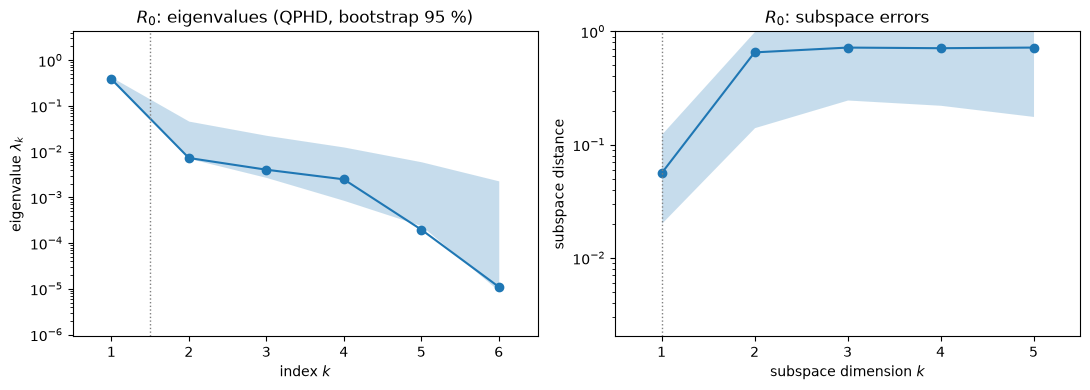

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, ax=axs[0])
ac.plotting.plot_subspace_errors(sub, ax=axs[1])
axs[0].set_title('$R_0$: eigenvalues (QPHD, bootstrap 95 %)')
axs[1].set_title('$R_0$: subspace errors')
print('mean bootstrap subspace distance for k = 1..5:', np.array2string(ac.mean_distance(sub)[:5], precision=3))
fig.tight_layout()
plt.close(fig)
fig

After the first, the eigenvalues fall to the fit's noise floor (bootstrap intervals shaded). The mean bootstrap distance between subspaces is 0.056 for $k = 1$ and 0.65 to 0.72 for $k = 2$ to 5, so only the one-dimensional subspace is well determined.

w1: hfact -0.809, kappa -0.487, f_he +0.257, f_w -0.161, core_radius +0.126, psepbqar_max -0.028
w2: f_w +0.921, f_he +0.317, core_radius +0.181, psepbqar_max +0.122, kappa -0.051, hfact -0.028


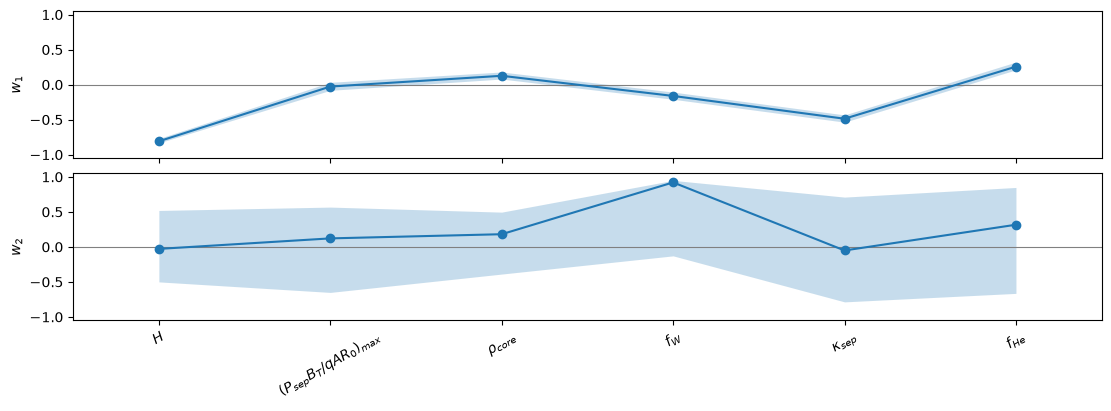

In [6]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=LABELS, interval='percentile',
                                         figsize=(11, 4))
for ax in axs:
    ax.tick_params(axis='x', labelrotation=30)
W = sub.W
for j in range(2):
    print(f'w{j + 1}:', ', '.join(f'{NAMES[i]} {W[i, j]:+.3f}' for i in np.argsort(-np.abs(W[:, j]))))
plt.close(fig)
fig

$\mathbf w_1$ is dominated by the H-factor ($-0.809$) and the elongation ($-0.487$): better confinement and a more elongated plasma both allow a smaller machine. Next are the He-4 fraction ($+0.257$; more helium dilutes the fuel and needs a larger machine), the W fraction ($-0.161$) and the core radius ($+0.126$); the divertor limit barely matters ($-0.028$). The second eigenvector is mostly the W fraction ($+0.921$), but $\lambda_2$ is small and v1 warns that its bootstrap replicates are poorly aligned, so $\mathbf w_2$ is not well determined by 62 runs; its bootstrap band spans most of $[-1, 1]$, while the band of $\mathbf w_1$ is narrow.

corr(w1^T x, R0) = 0.986


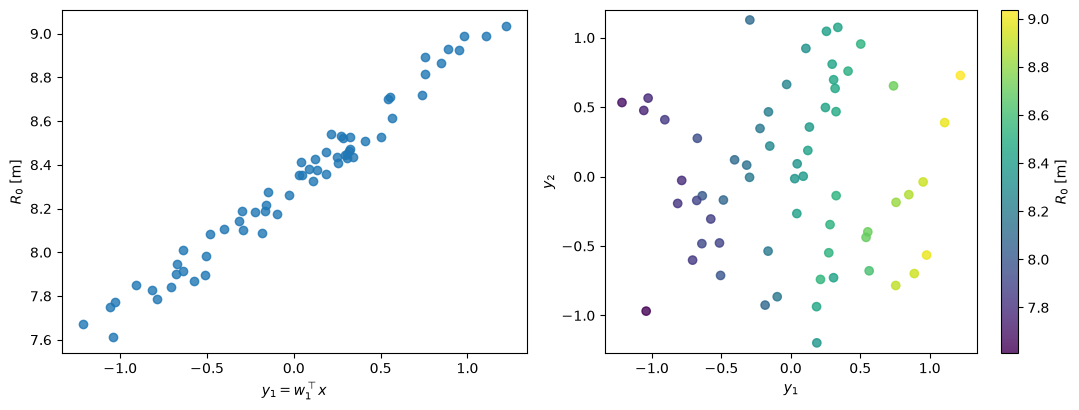

In [7]:
y = Xn @ W[:, :2]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub, X=X, f=R0, dims=1, qoi_label='$R_0$ [m]', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub, X=X, f=R0, dims=2, qoi_label='$R_0$ [m]', ax=axs[1])
print(f'corr(w1^T x, R0) = {np.corrcoef(y[:, 0], R0)[0, 1]:.3f}')
fig.tight_layout()
plt.close(fig)
fig

The one-dimensional summary plot is a tight, slightly curved trend: the correlation of $\mathbf w_1^T\mathbf x$ with $R_0$ is 0.986. In the two-dimensional plot the colour changes along $y_1$ and shows no clear pattern along $y_2$.

### How much of the scatter is the optimiser?

$R_0$ is a local optimum found by VMCON, and every stored run starts from the optimum at the baseline point. Rerunning two rows from the deck's own starting values, with $R_0$ started at 9.0 m (`DATA.md`, "Accuracy"), gave a nearly equal optimum at row 1 and a markedly smaller one at row 5, so the stored $R_0$ carries some optimiser dependence. The cell compares that with the scatter about the one-dimensional trend and refits the subspace with the two cold-start values.

In [8]:
# Start-point check (DATA.md, "Accuracy"): rows 1 and 5 rerun from the deck's own starting values
# (cold start) instead of the baseline optimum used for the stored runs.
COLD = {1: 7.985381440115837, 5: 7.487683538356137}
idx = col['index'][conv].astype(int)
f_cold = R0.copy()
for i, v in COLD.items():
    print(f'row {i}: stored (warm start) R0 = {R0[idx == i][0]:.4f} m, cold start {v:.4f} m, '
          f'difference {v - R0[idx == i][0]:+.4f} m')
    f_cold[idx == i] = v
sub_c = ac.active_subspace(space=space, X=X, f=f_cold, estimator='qphd')
print(f'with the two cold-start values: lambda1/lambda2 = {sub_c.eigenvalues[0] / sub_c.eigenvalues[1]:.1f}, '
      f'|w1 . w1(stored)| = {abs(sub_c.W[:, 0] @ W[:, 0]):.4f}')
res1 = R0 - np.polyval(np.polyfit(y[:, 0], R0, 2), y[:, 0])
print(f'residual of R0 about a quadratic in w1^T x: standard deviation {res1.std():.4f} m, largest {np.abs(res1).max():.4f} m')

row 1: stored (warm start) R0 = 7.9845 m, cold start 7.9854 m, difference +0.0009 m
row 5: stored (warm start) R0 = 7.6722 m, cold start 7.4877 m, difference -0.1846 m
with the two cold-start values: lambda1/lambda2 = 55.4, |w1 . w1(stored)| = 0.9999
residual of R0 about a quadratic in w1^T x: standard deviation 0.0557 m, largest 0.1105 m


At row 1 the two starts agree to 0.9 mm; at row 5 (high H-factor and elongation, the corner of the smallest machines) the cold start finds an optimum 0.185 m smaller. That is larger than the scatter about the one-dimensional trend (standard deviation 0.056 m, largest 0.111 m), so some of that scatter is likely optimiser dependence and not structure in $R_0$. Replacing these two values does not move $\mathbf w_1$ ($|\mathbf w_1\cdot\mathbf w_1(\text{stored})| = 0.9999$; $\lambda_1/\lambda_2 = 55.4$). The other 60 stored values were not rerun from another start, so how much of the scatter about the trend, and of $\lambda_2$, is optimiser dependence is not known.

### Surrogate on the active variable

polynomial of degree 2 in 1 active variable(s): LOO R^2 = 0.9728
polynomial of degree 3 in 1 active variable(s): LOO R^2 = 0.9724
polynomial of degree 2 in 2 active variable(s): LOO R^2 = 0.9871


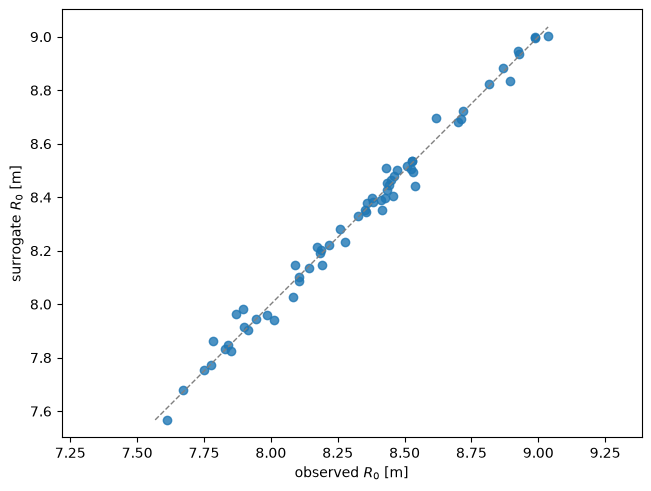

In [9]:
loo = {}
for n_dim, deg in [(1, 2), (1, 3), (2, 2)]:
    s = ac.fit_surrogate(X=X, f=R0, space=space, subspace=ac.with_dimension(sub, n_dim), kind='poly',
                         degree=deg)
    loo[n_dim, deg] = s.loo_r_squared
    print(f'polynomial of degree {deg} in {n_dim} active variable(s): LOO R^2 = {s.loo_r_squared:.4f}')
sur = ac.fit_surrogate(X=X, f=R0, space=space, subspace=ac.with_dimension(sub, 2), kind='poly', degree=2)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=R0, qoi_label='$R_0$ [m]')
plt.close(fig)
fig

A quadratic in the one active variable has leave-one-out $R^2 = 0.973$ (a cubic does not improve it, 0.972), close to the full 28-coefficient quadratic in all six inputs (0.978) with 3 coefficients instead of 28. Adding the second active variable raises it to 0.987.

## Comparison with the paper

The paper reports no active subspace. It ranks the inputs by *pinching* (Table III, Eq. (1)): the score of input $k$ is $1 - \mathrm{width}_k/\mathrm{width}_{total}$, where the widths are of the $R_0$ interval over its 6600 samples with all inputs free and with input $k$ fixed at its baseline. With 62 runs we cannot pinch the samples themselves, so the cell below pinches the full quadratic fit over $2^{16}$ Sobol' points of the box (seed 675), and also lists v1's activity scores ($\sum_j \lambda_j w_{kj}^2$ over the first $n$ eigenvectors).

In [10]:
# Pinching scores (Eq. (1) of the paper) on the full quadratic fit: R0 range over 2^16 Sobol' points of
# the box, with all six inputs free and with one input fixed at its Table I baseline.
Z = qmc.Sobol(d=m, scramble=True, seed=SEED).random_base2(16) * 2 - 1
q_all = quad_design(Z) @ coef
width_all = np.ptp(q_all)
base_n = space.to_normalized(BASE[None, :])[0]
score = {}
for k in range(m):
    Zk = Z.copy()
    Zk[:, k] = base_n[k]
    score[NAMES[k]] = 1 - np.ptp(quad_design(Zk) @ coef) / width_all
act = ac.activity_scores(sub, n=1)
act2 = ac.activity_scores(sub, n=2)
paper_score = dict(zip(NAMES, [0.2766, 0.0075, 0.0186, 0.1130, 0.1647, 0.3935]))   # Table III
print(f'quadratic-surrogate R0 range over the box: {q_all.min():.3f} to {q_all.max():.3f} m (width {width_all:.3f})')
print(f"{'input':>13}  {'paper pinch':>11}  {'quad pinch':>10}  {'act. score n=1':>14}  {'n=2':>7}  {'w1':>7}")
for k in np.argsort([-paper_score[n] for n in NAMES]):
    print(f'{NAMES[k]:>13}  {paper_score[NAMES[k]]:11.4f}  {score[NAMES[k]]:10.4f}  {act[k]:14.3e}  '
          f'{act2[k]:7.3e}  {W[k, 0]:+7.3f}')
print('rank by paper pinching :', [NAMES[k] for k in np.argsort([-paper_score[n] for n in NAMES])])
print('rank by quad pinching  :', [NAMES[k] for k in np.argsort([-score[n] for n in NAMES])])
print('rank by activity (n=1) :', [NAMES[k] for k in np.argsort(-act)])
print('rank by activity (n=2) :', [NAMES[k] for k in np.argsort(-act2)])
low_k = X_all[:, 4] <= 1.80
print(f'runs with kappa <= 1.80: {low_k.sum()}, converged {np.sum(low_k & conv)} (paper Fig. 2: none feasible)')
print(f'R0 of converged runs: [{R0.min():.3f}, {R0.max():.3f}] m, width {np.ptp(R0):.3f} m '
      '(paper Table II: [7.929, 10.322], width 2.393, from 6600 runs)')

quadratic-surrogate R0 range over the box: 7.259 to 9.615 m (width 2.356)
        input  paper pinch  quad pinch  act. score n=1      n=2       w1
         f_he       0.3935      0.1185       2.550e-02  2.623e-02   +0.257
        hfact       0.2766      0.4566       2.528e-01  2.529e-01   -0.809
        kappa       0.1647      0.2477       9.165e-02  9.166e-02   -0.487
          f_w       0.1130      0.1422       1.007e-02  1.624e-02   -0.161
  core_radius       0.0186      0.0752       6.164e-03  6.403e-03   +0.126
 psepbqar_max       0.0075      0.0093       2.927e-04  4.002e-04   -0.028
rank by paper pinching : ['f_he', 'hfact', 'kappa', 'f_w', 'core_radius', 'psepbqar_max']
rank by quad pinching  : ['hfact', 'kappa', 'f_w', 'f_he', 'core_radius', 'psepbqar_max']
rank by activity (n=1) : ['hfact', 'kappa', 'f_he', 'f_w', 'core_radius', 'psepbqar_max']
rank by activity (n=2) : ['hfact', 'kappa', 'f_he', 'f_w', 'core_radius', 'psepbqar_max']
runs with kappa <= 1.80: 22, converged 21 (

| quantity | paper [[1]](https://doi.org/10.1109/TPS.2022.3180233) | this notebook |
|---|---|---|
| PROCESS version, deck | 2022 version (not stated); EU H-mode DEMO baseline deck (not published) | v3.4.2; `large_tokamak_IN.DAT` with the edits above |
| design | 6600 Latin hypercube samples, uniform on Table I | first 64 points of a scrambled Sobol' sequence, uniform on Table I |
| converged (feasible) runs | not reported as a count; none at $\kappa \le 1.80$ (Fig. 2) | 62 of 64; 21 of 22 at $\kappa \le 1.80$; both failures at $f_{He} \le 0.064$ |
| $R_0$ at the baseline point | 9.0 m (the published EU DEMO value cited from Siccinio et al., p. 4443) | 8.357 m (our optimum) |
| $R_0$ interval (Table II) | [7.929, 10.322] m, width 2.393 m | runs: [7.611, 9.037] m, width 1.425 m; quadratic fit over the box: [7.259, 9.615] m, width 2.356 m |
| trend of $R_0$ with H (Fig. 1) | decreasing, about $-1.1$ m across [1.0, 1.3] (read from the fitted line) | decreasing, $-0.97$ m (linear fit) |
| trend with elongation (Fig. 2) | decreasing, about $-1.0$ m across [1.80, 1.90] (read from the fitted line) | decreasing, $-0.60$ m across [1.75, 1.90] (linear fit) |
| trend with He-4 fraction (Fig. 3) | increasing, about $+0.75$ m across [0.06, 0.12] (read from the fitted line) | increasing, $+0.29$ m (linear fit) |
| ranking (Table III pinching) | He-4 0.3935 > H 0.2766 > elongation 0.1647 > W 0.1130 > core radius 0.0186 > divertor 0.0075 | quadratic-fit pinching: H 0.4566 > elongation 0.2477 > W 0.1422 > He-4 0.1185 > core radius 0.0752 > divertor 0.0093 |
| ranking by activity score ($n = 1$) | not reported | H > elongation > He-4 > W > core radius > divertor |
| active subspace | not reported | $n = 1$: $\lambda_1$ holds 96.5 % of the trace and $\mathbf w_1$ is stable; $\lambda_2$ is at the fit's noise floor, so the size of $\lambda_1/\lambda_2$ (53.2 here; bootstrap 8.5 to 55.4) is not determined |

The three inputs the paper singles out (H-factor, elongation, He-4 fraction) are the three largest weights of $\mathbf w_1$, the directions of their trends agree with Figs. 1–3, and the divertor limit and core radius are the least important in every ranking, as in Table III. The order differs: here the H-factor leads clearly, and the He-4 fraction is third by activity and fourth by quadratic pinching, where the paper puts it first. Our $R_0$ trends are weaker and the sample range is narrower than the paper's. We cannot separate the causes, which include the different deck and PROCESS version (for example, our deck makes the He-4 fraction an input while keeping the deck's $\tau_\alpha/\tau_E \ge 5$ constraint, and our runs are feasible at low elongation where the paper's were not), the 64 runs against 6600, the optimiser's dependence on its starting point (above), and the fact that pinching on sample extremes depends on the few most extreme samples. That the quadratic fit's range over the box (2.356 m) is close to the paper's sample range (2.393 m) is a coincidence of two different things and not evidence of agreement.

In [11]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 2.4 s


## References

[1] E. Miralles-Dolz, A. Pearce, J. Morris and E. Patelli, Toward DEMO power plant concept selection under epistemic uncertainty, *IEEE Transactions on Plasma Science* 50(11):4440–4445, 2022. [doi:10.1109/TPS.2022.3180233](https://doi.org/10.1109/TPS.2022.3180233)

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] M. Kovari, R. Kemp, H. Lux, P. Knight, J. Morris and D. J. Ward, "PROCESS": A systems code for fusion power plants—Part 1: Physics, *Fusion Engineering and Design* 89(12):3054–3069, 2014. [doi:10.1016/j.fusengdes.2014.09.018](https://doi.org/10.1016/j.fusengdes.2014.09.018)

[4] M. Kovari, F. Fox, C. Harrington, R. Kembleton, P. Knight, H. Lux and J. Morris, "PROCESS": A systems code for fusion power plants – Part 2: Engineering, *Fusion Engineering and Design* 104:9–20, 2016. [doi:10.1016/j.fusengdes.2016.01.007](https://doi.org/10.1016/j.fusengdes.2016.01.007)

[5] K.-C. Li, On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma, *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)

[6] M. Siccinio et al., DEMO physics challenges beyond ITER, *Fusion Engineering and Design* 156:111603, 2020. [doi:10.1016/j.fusengdes.2020.111603](https://doi.org/10.1016/j.fusengdes.2020.111603)

PROCESS: https://github.com/ukaea/PROCESS, tag v3.4.2 (MIT licence).

## Acknowledgments

From [1] (first-page footnote, p. 4440): "This work was supported in part by the Engineering and Physical Sciences Research Council (EPSRC) and in part by Economic and Social Research Council (ESRC) Centre for Doctoral Training (CDT) in Risk and Uncertainty established within the Institute for Risk and Uncertainty at the University of Liverpool under Grant EP/L015927/1." The paper's Acknowledgment (p. 4444) reads: "The authors would like to thank the reviewers for their comments that helped to improve the manuscript. The authors would like to thank the U.S. Office of Naval Research (ONR) and the Princeton Plasma Physics Laboratory (PPPL) for providing the Student Travel Grant that made it possible to present this work at the 19th IEEE Symposium on Fusion Engineering. This work was undertaken on Barkla, part of the High Performance Computing facilities at the University of Liverpool, U.K. This work has been carried out within the framework of the EUROfusion Consortium, funded by the European Union through the Euratom Research and Training Programme under Grant 101052200—EUROfusion. Views and opinions expressed are however those of the author(s) only and do not necessarily reflect those of the European Union or the European Commission. Neither the European Union nor the European Commission can be held responsible for them."